# 微分器

入力の電圧の**変化の速さ**を出力する回路です。入力が一定なら出力は 0(Vref)、入力が速く変わるほど出力は大きくなります。位置から速さを求める、変化の始まりを検出する、といった計算をアナログで行います。[積分器](01_integrator.ipynb)と逆の働きです。

この回では、三角波を方形波にする、方形波の切り替わりでとげが出る、ボード線図、の 3 つを見ます。

## 回路

![微分器](02_differentiator/circuit.svg)

反転増幅の入力の抵抗を**コンデンサ C** に置きかえた回路です。C と直列の $R_s$ は、高い周波数でゲインが大きくなりすぎないように制限します。+ 入力は信号のグランド(Mimic の Vref)につなぎます。

教科書の回路は**反転**します。Mimic の微分器は反転しません。

## 原理

コンデンサに流れる電流は、電圧の変化の速さに比例します($i = C\,dV/dt$)。その電流が $R_f$ に流れるので、出力は入力の**微分**になります(導出は省きます)。

$$V_\mathrm{out} = -\tau_d\,\frac{dV_\mathrm{in}}{dt}, \qquad \tau_d = R_f C \quad(\text{Mimic では符号は +})$$

$\tau_d$ を**微分時間**といいます。**入力が 1 V/s の速さで変わると、出力は $\tau_d$ [s] × 1 V になります**。

| 入力 | 出力 |
|---|---|
| 一定の電圧 | 0(Vref) |
| 一定の傾きの直線 | 一定の電圧(= 傾き × $\tau_d$) |
| 三角波 | 方形波 |
| 方形波 | 切り替わりの瞬間だけの、細いとげ |
| 正弦波 | 位相が 90° 進んだ正弦波、振幅は $2\pi f \tau_d$ 倍 |

周波数で見ると、ゲインは $2\pi f\tau_d$ で、周波数が 10 倍で 10 倍(+20 dB/decade)です。ゲインが 1 になる周波数 $f_d = 1/(2\pi\tau_d)$ より高い周波数ほど大きく増幅するので、**高い周波数の雑音を大きくしてしまう**のが弱点です。

**制限**:$R_s$ を入れると、$\tau_\mathrm{lim} = R_s C$ より速い変化に対しては、ゲインが $\tau_d / \tau_\mathrm{lim} = R_f / R_s$ で頭打ちになります。

![微分器の周波数特性(模式図)](02_differentiator/response.svg)

## Mimic の設定と回路定数

| Mimic(Python) | ライブラリ(Arduino) | 回路 |
|---|---|---|
| `lab.mimic.differentiator(tau_d, limit)` | `mimic.setDifferentiator(tau_d, limit)` | $\tau_d = R_f C$、$\tau_\mathrm{lim} = R_s C$(どちらも µs。`limit` を省くと 10 µs) |

例:$\tau_d$ = 5 ms は、C = 0.1 µF、$R_f$ = 50 kΩ にあたります。$\tau_\mathrm{lim}$ = 1 ms なら $R_s$ = 10 kΩ で、高い周波数のゲインは 5 倍で頭打ちになります。

**この測定器での注意**:信号発生器は 50 µs ごとに値を書き換える**階段**です。微分器は、この小さな段のひとつひとつを「急な変化」として拾います。そのため、この講義では制限の時定数を 1 ms 程度と長めにして、段をならしています(やってみようで、短くするとどうなるかを見ます)。

## 準備:測定器につなぐ

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
from mimiclab import MimicLab, Monitor, fit_sine, match_phase, plot_waveforms

lab = MimicLab()  # finds the Arduino; or MimicLab("COM5")
lab

MimicLab(port='COM4', ver=0.1.0, mimic=20261125)

## 実験 1:三角波を方形波にする

20 Hz、振幅 1 V の三角波を入れます。三角波は半周期(25 ms)で 2 V 変わるので、傾きは ±80 V/s です。$\tau_d$ = 5 ms なら、出力は ±80 V/s × 5 ms = **±0.4 V** の方形波になるはずです。

output - Vref: +0.391 V while rising, -0.396 V while falling (theory +-0.400 V)


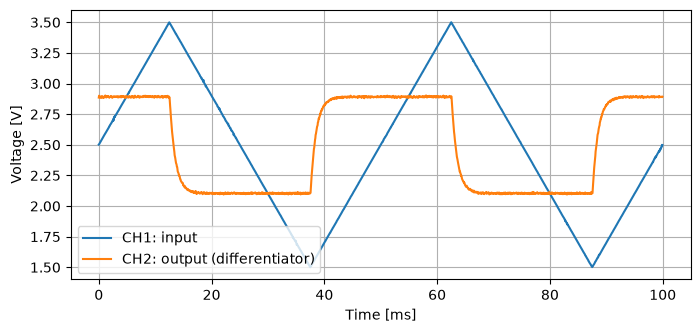

In [2]:
TAU_D = 5000    # differentiation time [us]
LIMIT = 1000    # limit time [us]

lab.mimic.differentiator(TAU_D, LIMIT)
lab.fg.triangle(20, 1.0)
time.sleep(0.3)
t, ch1, ch2 = lab.scope.capture(2000)   # 0.1 s: two periods
ph = t % 0.05                                   # time in the period (50 ms); corners at 12.5 and 37.5 ms
rising = (ph > 0.0425) | (ph < 0.0075)          # the input goes up (5 ms away from the corners)
falling = (ph > 0.0175) & (ph < 0.0325)         # the input goes down
print(f"output - Vref: {ch2[rising].mean() - 2.5:+.3f} V while rising, "
      f"{ch2[falling].mean() - 2.5:+.3f} V while falling (theory +-{80 * TAU_D * 1e-6:.3f} V)")
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(t * 1e3, ch1, label="CH1: input")
ax.plot(t * 1e3, ch2, label=f"CH2: output (differentiator)")
ax.set_xlabel("Time [ms]")
ax.set_ylabel("Voltage [V]")
ax.grid(True)
ax.legend()
plt.show()

出力の平らな部分に見える細かいぎざぎざは、信号発生器の階段(50 µs ごと)を微分したものです。

## 実験 2:方形波を入れる

20 Hz、振幅 0.1 V の方形波を入れます。入力が一定のあいだは出力は 0(Vref)で、切り替わりの瞬間だけ、とげが出ます。理想の微分器なら、とげは無限に高く細くなりますが、制限があるので、高さは段差 × $\tau_d/\tau_\mathrm{lim}$ = 0.2 V × 5 = **1 V** で、$\tau_\mathrm{lim}$ = 1 ms で戻ります(1 次の HPF と同じ形です)。

spike: +0.953 V and -0.960 V (theory +-1.0 V)


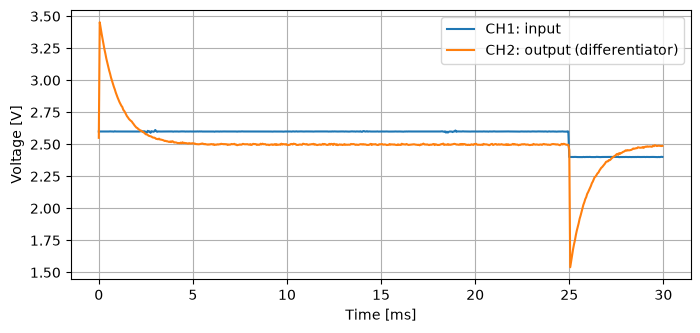

In [3]:
lab.mimic.differentiator(5000, 1000)
lab.fg.square(20, 0.1)
time.sleep(0.3)
t, ch1, ch2 = lab.scope.capture(600)   # 30 ms
print(f"spike: {ch2.max() - 2.5:+.3f} V and {ch2.min() - 2.5:+.3f} V (theory +-1.0 V)")
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(t * 1e3, ch1, label="CH1: input")
ax.plot(t * 1e3, ch2, label=f"CH2: output (differentiator)")
ax.set_xlabel("Time [ms]")
ax.set_ylabel("Voltage [V]")
ax.grid(True)
ax.legend()
plt.show()

とげの高さが理論(1 V)より少し低いのは、入力の段差が一瞬ではないためです。信号発生器の DAC は 50 µs ごとの階段で、Mimic の入力のフィルタでもなまるので、段差は数十 µs かけて変わります。そのあいだに出力は少し戻り始めるので、山は $\tau_\mathrm{lim}$ = 1 ms に比べたその時間のぶんだけ低くなります。

## 実験 3:ボード線図

$\tau_d$ = 1.59 ms($f_d$ = 100 Hz)、制限 159 µs(高い周波数のゲイン 10 倍、角の周波数 1 kHz)にして、周波数特性を測ります。ゲインは +20 dB/decade で上がり、100 Hz で 0 dB、1 kHz の上で 20 dB に近づくはずです。位相は +90° から始まります。高い周波数ではゲインが大きいので、振幅は 0.2 V にします。

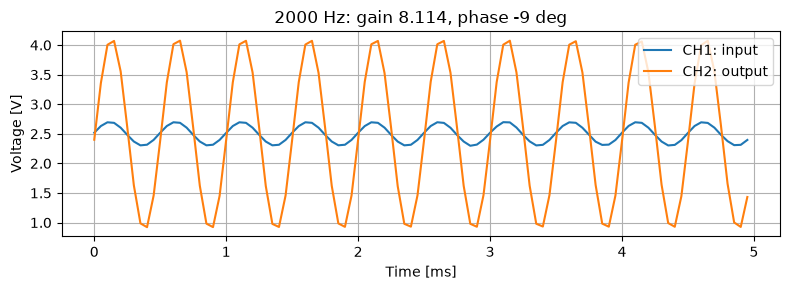

In [4]:
TAU_D, LIMIT = 1592, 159   # [us]
FD = 1e6 / (2 * np.pi * TAU_D)
R = LIMIT / TAU_D
freqs = np.logspace(1, np.log10(2000), 16)
f_th = np.logspace(1, np.log10(2000), 200)

lab.mimic.differentiator(TAU_D, LIMIT)
r = lab.frequency_response(freqs, amp=0.2, monitor=True)

各周波数で取り込んだ波形です(クリックで開きます)。


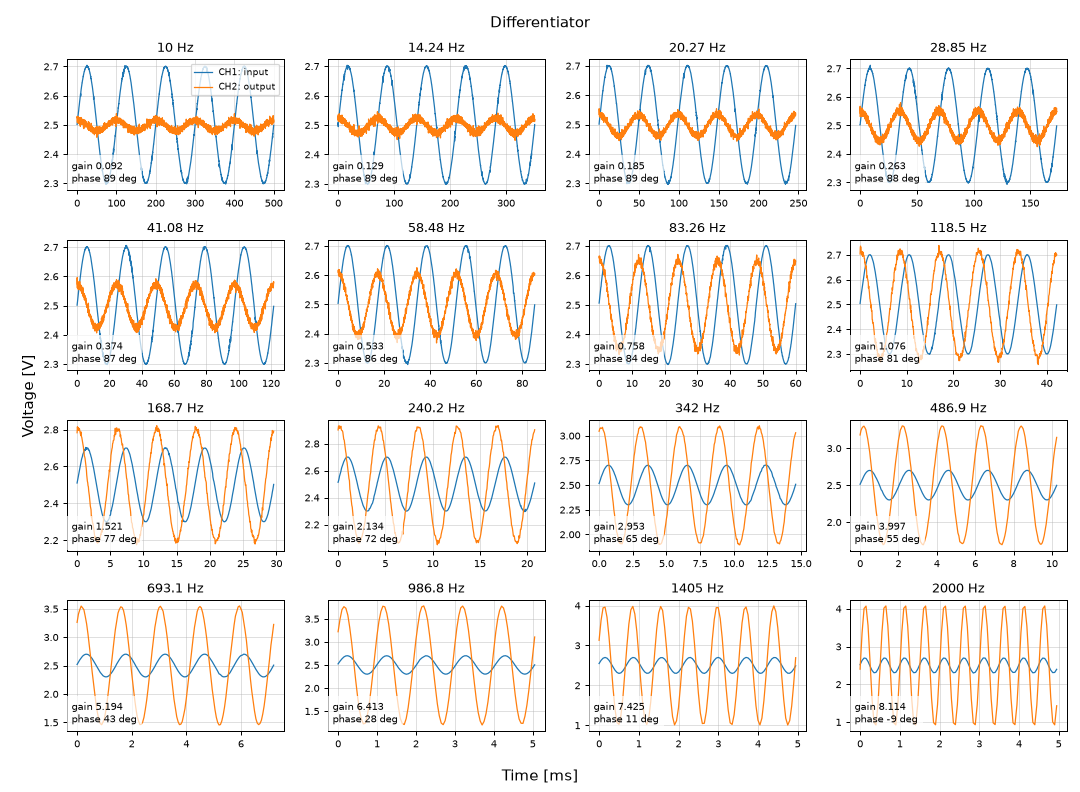

In [5]:
plot_waveforms(r, title="Differentiator", collapsed=True)

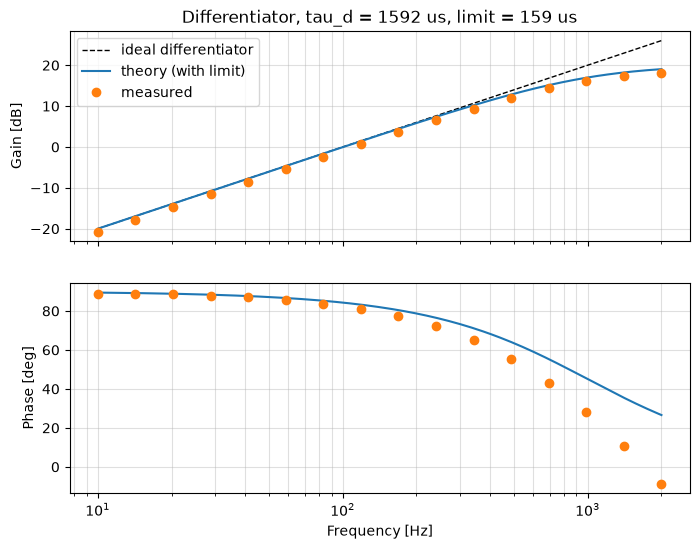

In [6]:
def h_diff(f):
    return (1j * f / FD) / (1 + 1j * R * f / FD)

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(8, 6), sharex=True)
ax1.semilogx(f_th, 20 * np.log10(abs(1j * f_th / FD)), "k--", lw=1, label="ideal differentiator")
ax1.semilogx(f_th, 20 * np.log10(abs(h_diff(f_th))), "-", label="theory (with limit)")
ax1.semilogx(r.freq, r.gain_db, "o", label="measured")
ax2.semilogx(f_th, np.degrees(np.angle(h_diff(f_th))), "-")
ax2.semilogx(r.freq, match_phase(r.phase, np.degrees(np.angle(h_diff(r.freq)))), "o")
ax1.set_title(f"Differentiator, tau_d = {TAU_D} us, limit = {LIMIT} us")
ax1.set_ylabel("Gain [dB]")
ax2.set_ylabel("Phase [deg]")
ax2.set_xlabel("Frequency [Hz]")
for ax in (ax1, ax2):
    ax.grid(True, which="both", alpha=0.4)
ax1.legend()
plt.show()

高い周波数で位相が理論より遅れるのは、測定器と Mimic の遅れ(約 50 µs)のためです([周波数特性を測る回](../02_filter1st/03_bode.ipynb))。

## やってみよう

下のセルの値(大文字の名前)を**1 つずつ**変えて実行し、オシロの波形と数値がどう変わるかを自分の目で確かめましょう。どの値を順に試すとよいかと、何が見えるはずかは「ヒント」に書いてあります。

> Run All で最後まで実行したあと(接続を閉じたあと)にやるときは、最初の「測定器につなぐ」のセルをもう一度実行してから始めます。

### 1. 微分時間を変える

三角波を入れたまま、$\tau_d$ を変えて、方形波の大きさを見ます。
<details><summary>ヒント</summary>

`TAU_D` を 5000 → 2000 → 10000 と変えてみましょう。出力は ±80 V/s × $\tau_d$ で、±0.4 V、±0.16 V、±0.8 V です。

</details>

theory: +-0.400 V around 2.5 V


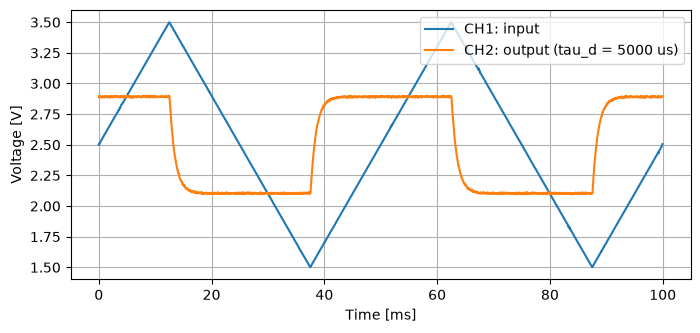

In [7]:
TAU_D = 5000   # [us]

lab.mimic.differentiator(TAU_D, 1000)
lab.fg.triangle(20, 1.0)
time.sleep(0.3)
t, ch1, ch2 = lab.scope.capture(2000)
print(f"theory: +-{80 * TAU_D * 1e-6:.3f} V around 2.5 V")
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(t * 1e3, ch1, label="CH1: input")
ax.plot(t * 1e3, ch2, label=f"CH2: output (tau_d = {TAU_D} us)")
ax.set_xlabel("Time [ms]")
ax.set_ylabel("Voltage [V]")
ax.grid(True)
ax.legend()
plt.show()

### 2. 制限を短くする

三角波を入れたまま、制限の時定数を短くしていきます。出力はどうなるでしょうか。
<details><summary>ヒント</summary>

`LIMIT` を 1000 → 200 → 50 → 10 と短くしてみましょう。だんだん、方形波の上にぎざぎざの雑音が大きく乗るようになります。信号発生器は 50 µs ごとの階段なので、制限が短いと、段のひとつひとつを急な変化として拾ってとげにするからです。微分器が「高い周波数の雑音を大きくする」ようすが、目で見えます。実際の回路でも、雑音を抑えるために $R_s$ を入れます。

</details>

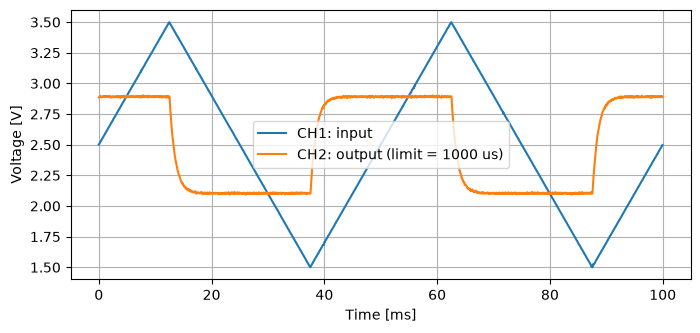

In [8]:
LIMIT = 1000   # [us]

lab.mimic.differentiator(5000, LIMIT)
lab.fg.triangle(20, 1.0)
time.sleep(0.3)
t, ch1, ch2 = lab.scope.capture(2000)
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(t * 1e3, ch1, label="CH1: input")
ax.plot(t * 1e3, ch2, label=f"CH2: output (limit = {LIMIT} us)")
ax.set_xlabel("Time [ms]")
ax.set_ylabel("Voltage [V]")
ax.grid(True)
ax.legend()
plt.show()

### 3. 正弦波を微分する

正弦波を入れて、周波数を変えます。振幅と位相はどう変わるでしょうか。
<details><summary>ヒント</summary>

`FREQ` を 10 → 20 → 50 と変えてみましょう。出力の振幅は $2\pi f\tau_d$ 倍(0.31、0.63、1.57 倍)で、周波数に比例して大きくなります。位相は +90° 進みます(入力の山より 4 分の 1 周期早く山が来る)。正弦波の微分は余弦波(位相が 90° 進んだ正弦波)です。

</details>

gain 0.308 (theory 0.314), phase 86.2 deg


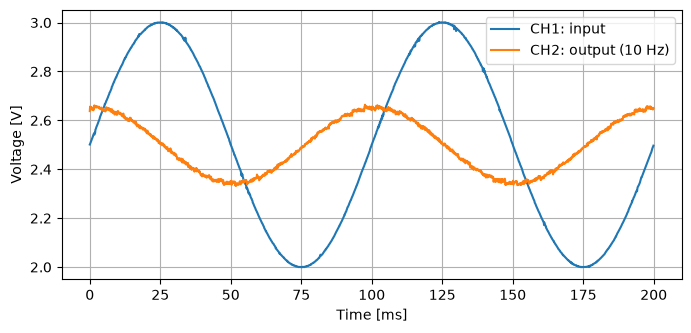

In [9]:
FREQ = 10   # [Hz]

lab.mimic.differentiator(5000, 1000)
lab.fg.sine(FREQ, 0.5)
time.sleep(0.3)
t, ch1, ch2 = lab.scope.capture(2000, fs=10000)   # 0.2 s
a1, p1, _ = fit_sine(t, ch1, FREQ)
a2, p2, _ = fit_sine(t, ch2, FREQ)
print(f"gain {a2 / a1:.3f} (theory {2 * np.pi * FREQ * 5e-3:.3f}), phase {(p2 - p1 + 180) % 360 - 180:.1f} deg")
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(t * 1e3, ch1, label="CH1: input")
ax.plot(t * 1e3, ch2, label=f"CH2: output ({FREQ} Hz)")
ax.set_xlabel("Time [ms]")
ax.set_ylabel("Voltage [V]")
ax.grid(True)
ax.legend()
plt.show()

## まとめ

- 微分器は入力の変化の速さを出す。出力 = 傾き × $\tau_d$($\tau_d = R_fC$)。三角波は方形波に、方形波はとげになる。
- 周波数で見ると +20 dB/decade、位相 +90°。高い周波数の雑音を大きくするので、$R_s$(制限 $\tau_\mathrm{lim}$)でゲインを頭打ちにする。
- Mimic では `differentiator(tau_d, limit)`(反転しない)。

最後に Mimic を素通し(バイパス)に戻して、接続を閉じます。

In [10]:
lab.mimic.bypass()
lab.fg.sine(100, 1.0)
lab.close()